# Inside SRAM: from RISC-V request to a 6T bitcell

**Authors:** Fiza Khalid and Dayem Mujahid.

Copyright 2026 Fiza Khalid and Dayem Mujahid

**License:** Apache License 2.0 (SPDX: Apache-2.0). See [LICENSE](../LICENSE).

**What this project demonstrates.** A small RISC-V memory request is traced through address decoding, a 4 × 4 logical SRAM array, a selected six-transistor cell, and a source-derived read or write lesson. Four executable experiments check the storage behavior before the interactive lesson begins.

Static random-access memory (SRAM) retains a bit while powered through cross-coupled inverter feedback, without a periodic refresh operation. Fast on-chip access makes SRAM useful for processor caches and local memories. The interaction between row selection, paired bit lines, and the internal latch is hard to see in a static circuit drawing. Here, students can inspect each logical phase and move backward without altering memory.

**Scope:** This is a binary behavioral teaching model. It does not calculate voltage, current, physical delay, power, noise margins, or silicon performance.

## 1. Setup and reproducibility

Use Python **3.10 or newer**. Recommended for reproducing this audit: **Python 3.13.6** with Matplotlib 3.11.2, ipywidgets 8.1.9, IPython 9.17.1, Notebook 7.6.2, IPykernel 7.3.0, nbformat 5.11.1, nbclient 0.11.0, and pytest 9.1.1. These are tested versions; `pyproject.toml` declares the supported minimums. From the repository root, create and activate a virtual environment, then run `python -m pip install -e ".[notebook,test]"`. Open this notebook in VS Code and select that environment's Python kernel. Use **Restart Kernel and Run All Cells**. The experiment cells assert their outcomes; the last cell launches the lesson.

For Google Colab, first clone this repository into the Colab runtime and run `%cd riscv-memory-visualizer` followed by `%pip install -e ".[notebook,test]"` in Colab cells. Then open this notebook from the cloned repository and restart/run all cells. Uploading only the `.ipynb` omits the package and causes `ModuleNotFoundError`. Colab widget rendering depends on its current widget support; local VS Code/Jupyter is the primary validated workflow.

In [1]:
from IPython.display import HTML, SVG, display
from riscv_memory_visualizer.memory.array import SRAMArray
from riscv_memory_visualizer.memory.periphery import read_sequence, write_sequence
from riscv_memory_visualizer.simulation.controller import MemoryEventEngine
from riscv_memory_visualizer.simulation.events import MemoryEventType
from riscv_memory_visualizer.simulation.teaching import SRAMTeachingController
from riscv_memory_visualizer.visualization.schematic_svg import render_scene

def show_table(headers, rows):
    from html import escape
    header = ''.join(f'<th style="padding:6px 10px;text-align:left;border-bottom:2px solid #8494a7">{escape(str(h))}</th>' for h in headers)
    body = ''.join('<tr>' + ''.join(f'<td style="padding:5px 10px;border-bottom:1px solid #dce3eb">{escape(str(value))}</td>' for value in row) + '</tr>' for row in rows)
    display(HTML(f'<table style="border-collapse:collapse;font:14px system-ui"><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

## 2. System architecture and address mapping

**RISC-V processor → memory interface → address decoder → SRAM array → selected 6T bitcell → peripheral circuits.** The processor supplies the access context; the memory event engine and array provide the actual result. The row decoder asserts one word line (WL). The column selector identifies the logical bit-line path at that row. BL and BL_bar form the complementary pair. Precharge/equalization prepares both lines for a read; the sense representation resolves their logical difference. A write driver applies complementary values for a write.

The default 4 × 4 array has **16 separate single-bit cells**. In this simplified educational mapping, aligned byte addresses are four bytes apart: `index = address // 4`, then `row, column = divmod(index, 4)`. For `lw x5,8(x2)`, the effective address is the value in `x2` plus offset 8; in this lesson `x2=0`, so the address is `0x08`.

**Worked example (zero-based):** `0x08` hexadecimal = 8 decimal. Logical index = `8 // 4 = 2`. Row = `2 // 4 = 0`; column = `2 % 4 = 2`. The selected cell is **(0,2)**; column 2 is the third column. The four-byte address-slot spacing does not mean that each bitcell stores a 32-bit word. The backend rejects unaligned, negative, and out-of-range addresses.

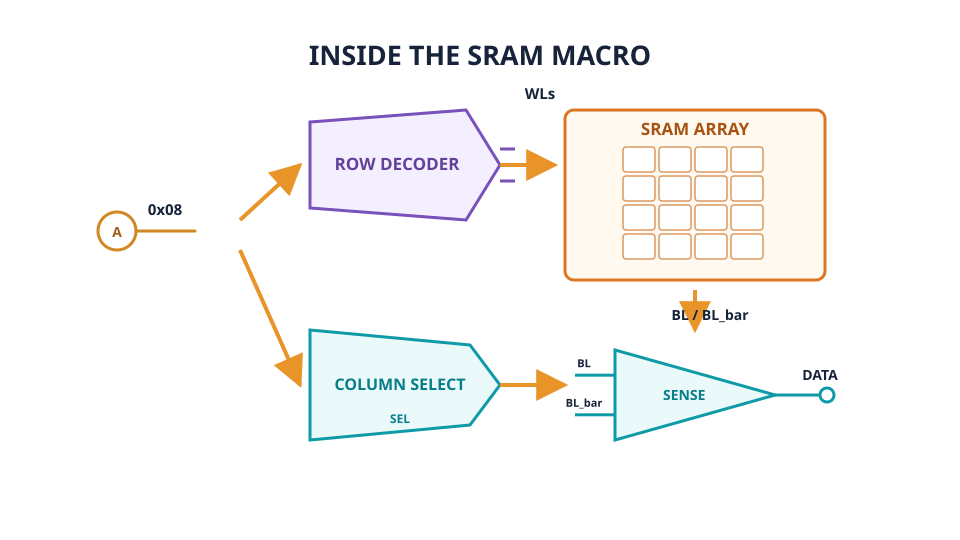

In [2]:
architecture = SRAMTeachingController('READ')
display(SVG(render_scene(architecture.steps[1])))

## 3. The six-transistor cell

M1 and M3 are PMOS pull-ups; M2 and M4 are NMOS pull-downs. These four devices make two cross-coupled inverters: each output drives the other inverter's input. The stable complementary nodes Q and Q_bar retain one bit while powered. M5 and M6 are WL-controlled NMOS access devices connecting Q/Q_bar to BL/BL_bar. The existing renderer below draws the same topology used in the interactive lesson. There is no storage capacitor in this 6T model.

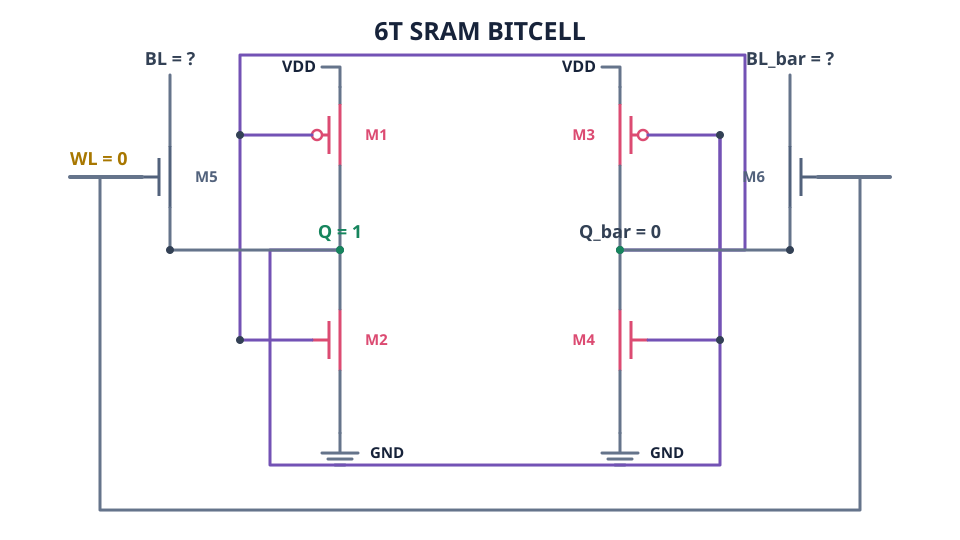

In [3]:
display(SVG(render_scene(next(step for step in architecture.steps if step.title == 'Cross-coupled inverters'))))

## 4. Read and write operations

**Read:** precharge both lines → raise WL → let stored Q/Q_bar establish a logical BL/BL_bar difference → sense it → return the stored bit. The read should leave Q unchanged.

**Write:** enable the driver → drive BL/BL_bar with the new bit and its complement → raise WL → overwrite Q/Q_bar → record the new bit. Cross-coupled feedback then retains the new binary state while powered. The example lesson starts at Q=0 and writes 1. In the existing array, selection remains active after an access, so the final snapshot correctly retains **WL=1**. It does not model a later word-line deactivation.

## 5. Experimental results and verification

Each case starts with a fresh 4 × 4 SRAM array. Setup writes and measured accesses both use `MemoryEventEngine`; no result is typed into the table. Assertions check the returned or stored bit, address decoding, and every unselected storage location. A failed assertion stops notebook execution.

In [4]:
cases = [('Read 0', 0, 'READ', None, 0),
         ('Read 1', 1, 'READ', None, 1),
         ('Write 0 → 1', 0, 'WRITE', 1, 1),
         ('Write 1 → 0', 1, 'WRITE', 0, 0)]
experiment_rows = []
for label, initial_bit, operation, write_value, expected in cases:
    array = SRAMArray(4, 4)
    engine = MemoryEventEngine(array)
    address = 8
    if initial_bit == 1:
        engine.write(address, 1)  # Explicit setup through the real backend.
    before = array.get_state()
    engine.timeline.clear()
    result = engine.read(address) if operation == 'READ' else engine.write(address, write_value)
    after = array.get_state()
    events = engine.timeline.events()
    decoded = next(event for event in events if event.event_type is MemoryEventType.ADDRESS_DECODE)
    access_type = MemoryEventType.SRAM_READ if operation == 'READ' else MemoryEventType.SRAM_WRITE
    access = next(event for event in events if event.event_type is access_type)
    row, column = decoded.row, decoded.column
    observed = after.cells[row][column]
    assert (decoded.address, row, column) == (address, 0, 2)
    assert before.cells[row][column] == initial_bit
    assert observed == expected and access.value == expected
    if operation == 'READ':
        assert result == expected and before.cells == after.cells
    else:
        assert result is None  # The write API returns None; the event records written data.
    assert all(before.cells[r][c] == after.cells[r][c]
               for r in range(4) for c in range(4) if (r, c) != (row, column))
    experiment_rows.append((label, f'{address:#04x} → ({row},{column})', initial_bit,
                            operation if write_value is None else f'WRITE {write_value}',
                            expected, result if operation == 'READ' else access.value,
                            observed, 'PASS'))
show_table(('Experiment', 'Address → cell', 'Initial Q', 'Operation', 'Expected',
            'Actual result', 'Final Q', 'Check'), experiment_rows)
print(f'{len(experiment_rows)} backend experiments passed; decode and unselected-cell checks passed in each case.')

Experiment,Address → cell,Initial Q,Operation,Expected,Actual result,Final Q,Check
Read 0,"0x08 → (0,2)",0,READ,0,0,0,PASS
Read 1,"0x08 → (0,2)",1,READ,1,1,1,PASS
Write 0 → 1,"0x08 → (0,2)",0,WRITE 1,1,1,1,PASS
Write 1 → 0,"0x08 → (0,2)",1,WRITE 0,0,0,0,PASS


4 backend experiments passed; decode and unselected-cell checks passed in each case.


## 6. Conceptual logical-state sequence

**Conceptual logical-state sequence — not SPICE simulation or measured analog timing.** The tables below come from the same peripheral snapshots as the teaching controller. `—` means the signal or result is not specified at that phase. Values are binary teaching states, not voltage levels or equal time intervals.

In [5]:
def phase_rows(phases):
    return [(phase.phase.value.replace('_', ' ').title(), phase.word_line,
             '—' if phase.bit_line is None else phase.bit_line,
             '—' if phase.bit_line_bar is None else phase.bit_line_bar,
             phase.q, phase.q_bar,
             '—' if phase.read_result is None and phase.phase.value != 'WRITE_COMPLETE'
                 else phase.read_result if phase.read_result is not None else phase.write_value)
            for phase in phases]
headers = ('Phase', 'WL', 'BL', 'BL_bar', 'Q', 'Q_bar', 'Result')
read_lesson = SRAMTeachingController('READ')
write_lesson = SRAMTeachingController('WRITE')
read_phases = [step.circuit_snapshot for step in read_lesson.steps if step.circuit_snapshot is not None]
write_phases = [step.circuit_snapshot for step in write_lesson.steps if step.circuit_snapshot is not None]
assert len(read_phases) == len(write_phases) == 5
assert write_phases[0].q == 0 and write_phases[-1].q == 1
assert write_phases[-1].word_line == write_lesson.array.get_cell(0, 2).word_line == 1
display(HTML('<h3>Read example: Q = 1</h3>'))
show_table(headers, phase_rows(read_phases))
display(HTML('<h3>Write example: Q = 0 → 1</h3>'))
show_table(headers, phase_rows(write_phases))

Phase,WL,BL,BL_bar,Q,Q_bar,Result
Precharge,0,1,1,1,0,—
Word Line Active,1,1,1,1,0,—
Bitline Development,1,1,0,1,0,—
Sense,1,1,0,1,0,—
Read Complete,1,1,0,1,0,1


Phase,WL,BL,BL_bar,Q,Q_bar,Result
Write Driver Active,0,—,—,0,1,—
Bitlines Driven,0,1,0,0,1,—
Word Line Active,1,1,0,0,1,—
Cell Overwrite,1,1,0,1,0,—
Write Complete,1,1,0,1,0,1


## 7. Verification, limitations, and references

The four experiments above check both read polarities, both write transitions, decode to cell `(0,2)`, and preservation of unselected bits. The repository's automated suite checks the model, lesson navigation and 18-step boundaries, SVG rendering, and other application behavior. From the repository root run `python -m pytest -q tests` and `python scripts/validate_notebook.py` in the installed environment. The validator executes the complete notebook and the final launch cell in separate fresh kernels.

**Implemented:** logical single-bit SRAM, a source-rendered six-device schematic, read/write snapshots, processor-linked lessons, backend-derived experiments, and software tests. **Future extensions:** circuit-level SPICE simulation, transistor sizing, a PDK, physical layout, full 32-bit word storage, and measured timing, power, and noise behavior. None of those physical results are claimed here. The periphery is a conceptual teaching representation; its phases do not establish analog transients or circuit accuracy.

**References and credits:** see [teaching model](../docs/teaching_model.md), [architecture notes](../docs/sram_architectures.md), [digital timing semantics](../docs/digital_timing.md), and the source modules under `src/riscv_memory_visualizer/`. Open-source Python dependencies are listed in `pyproject.toml`. This project is licensed under Apache License 2.0; see [LICENSE](../LICENSE) and [AUTHORS.md](../AUTHORS.md).

## 8. Interactive 18-step lesson

Choose **Read** or **Write**. Use **Next**, **Previous**, and **Restart** to inspect each source-derived scene and its **WHAT IS HAPPENING?** explanation. Navigation only changes the displayed immutable snapshot. The Read story executes `lw x5,8(x2)` after explicitly storing 1; the Write story executes `addi x1,x0,1` and `sw x1,8(x2)` to change 0 to 1. Both select address `0x08`, row 0, column 2.

In [1]:
from riscv_memory_visualizer.ui.teaching_app import SRAMTeachingApp

app = SRAMTeachingApp()
app.display()